# Assignment 1: Motor parameter identification

Motors of my robot: M3/E3 left wheel, M4/E4 right wheel. Wheels spun freely in the air.


## 1. Motor model
Without the inductance, the motor is a first-order system:

$$\frac{d\omega}{dt}=\frac{U}{T_m k_e}-\frac{\omega}{T_m},\qquad \frac{d\theta}{dt}=\omega$$

**Parameters**

- $U$ [V]: the voltage on the motor. TRIK only sets PWM, so $U=\mathrm{PWM}/100\cdot U_{battery}$.
- $\theta$ [rad] - the wheel angle from the encoder,
- $\omega$ [rad/s] - how fast the wheel angle changes.
- $\omega_{ss}$ [rad/s]: the constant speed the motor reaches if $U$ stays the same.
- $T_m$ [s]: how fast the motor gets there. After $T_m$ it has 63 % of $\omega_{ss}$.
- $k_e$ [V·s/rad]: the volts needed for 1 rad/s of steady speed, so $\omega_{ss}=U/k_e$.

**$\theta(t)$ for a step** ($U$ constant from $t=0$, motor at rest)

- Speed: $\omega(t)=\omega_{ss}(1-e^{-t/T_m})$ with $\omega_{ss}=U/k_e$. It starts at 0, and both sides of the equation equal $\omega_{ss}e^{-t/T_m}/T_m$.
- Angle, integrating from $\theta(0)=0$:

$$\theta(t)=\int_0^t\omega_{ss}\left(1-e^{-s/T_m}\right)ds=\omega_{ss}\left(t-T_m+T_m e^{-t/T_m}\right)$$

- After a few $T_m$: $\theta\approx\omega_{ss}(t-T_m)$. The slope gives $\omega_{ss}$ and the shift gives $T_m$.

**Assumptions** (each one is tested by my data)

- No inductance: Figure 1a.
- Linear viscous friction, so $\omega_{ss}\propto U$: Figure 1b and section 4.
- Constant load: wheels in the air, yet $T_m$ changes (Figure 1c).
- Constant battery voltage in a run: `battery.txt`.



## 2. Test signals
All 9 runs were done in one session, in this order, with the wheels in the air. Each TRIK block program logs `angle,time,PWM` in every loop (Timer 5 ms), ends with 1 s at PWM 0 (coasting, still logged), and writes the battery voltage before and after the run to `battery.txt`. Amplitudes stay at or below 60 %, below the 80 % limit in the design rules, so the motor never saturates.

**Step series:** 3 s motor off, then −100 to +100 % in 10 % steps (0 skipped), each 2 s on and 1 s at PWM 0.
1. `steps_M4.txt` (M4): the main identification run. Each 2 s step gives $\omega_{ss}$ and $T_m$ at that PWM (Table 1), and from them $k_e$ (Table 2). The first 3 s check zero drift, and the 1 s after each step is coasting, which gives the friction (4.2).
2. `steps_M4_run2.txt` (M4 again): the same program on the same motor, right after run 1. It checks repeatability: if the numbers match, the differences between motors and directions are real, not noise.
3. `steps_M3.txt` (M3): run 1 for the other motor, so the two motors can be compared.

**Square wave + chirp:** ±60 %, period 1 s for 4 s, then a chirp from 0.2 to 3 Hz for 10 s.

4. `signal_M4.txt` (M4) and 5. `signal_M3.txt` (M3): the complex signal. The models are built from the steps only, so this tests whether they predict an input they have never seen (Table 6, Figure 3). The square wave reverses direction every 0.5 s, which would show gear backlash; the chirp gets faster until the motor can no longer follow.

**Slow triangle:** ±50 %, period 40 s, 2 periods. PWM changes by only 5 % per second.

6. `triangle_M4.txt` and 7. `triangle_M3.txt`: PWM passes slowly through every whole percent in both directions. This measures the dead zone to 1 %, which 10 % steps cannot, and shows the S-shaped speed curve near zero (Figure 2a). It is also the third test of the models (Table 6).

**Slow chirp:** ±60 %, 0.1 to 2 Hz over 30 s.

8. `chirp_M4.txt` and 9. `chirp_M3.txt`: sine waves that get faster, from well below to above the motor's corner frequency $1/(2\pi T_m)\approx 1$ Hz. They give the frequency response, meaning how much speed the motor gives per volt at each frequency, compared with the course formula (Figure 4). The signal is symmetric, so any net turn shows backward ≥ forward: the wheel drifts 13.1 and 17.2 rad forward (5.1).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize
from scipy.integrate import odeint
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'legend.fontsize': 8, 'figure.constrained_layout.use': True})

if not os.path.isdir('motor_data'):
    from google.colab import files
    os.makedirs('motor_data')
    os.chdir('motor_data')
    files.upload()
    os.chdir('..')

def load(name):                                                           # file columns: angle [deg], time [ms], PWM [%]
    angle, time, pwm = np.loadtxt('motor_data/' + name, delimiter=',', unpack=True)
    return angle * np.pi / 180, time / 1000, pwm                          # SI: rad, s

def speed(theta, t):                                                      # np.gradient, then a moving average of 3 samples
    return pd.Series(np.gradient(theta, t)).rolling(3, center=True, min_periods=1).mean().values

MOTORS = ['M3', 'M4']                                                     # M3 left wheel, M4 right wheel
NAME = {1: 'forward', -1: 'backward'}
bat = pd.read_csv('motor_data/battery.txt', names=['file', 'U_before', 'U_after'], index_col='file')   # written by the robot
bat['U'] = (bat.U_before + bat.U_after) / 2                               # battery voltage of each run [V]
bat.round(3)

Saving battery.txt to battery.txt
Saving chirp_M3.txt to chirp_M3.txt
Saving chirp_M4.txt to chirp_M4.txt
Saving signal_M3.txt to signal_M3.txt
Saving signal_M4.txt to signal_M4.txt
Saving steps_M3.txt to steps_M3.txt
Saving steps_M4.txt to steps_M4.txt
Saving steps_M4_run2.txt to steps_M4_run2.txt
Saving triangle_M3.txt to triangle_M3.txt
Saving triangle_M4.txt to triangle_M4.txt


,U_before,U_after,U
file,,,
steps_M4.txt,11.545,11.545,11.545
steps_M4_run2.txt,11.545,11.532,11.539
steps_M3.txt,11.532,11.519,11.526
signal_M4.txt,11.532,11.532,11.532
signal_M3.txt,11.506,11.519,11.513
triangle_M4.txt,11.532,11.519,11.526
triangle_M3.txt,11.519,11.506,11.513
chirp_M4.txt,11.506,11.493,11.500
chirp_M3.txt,11.493,11.493,11.493


**Battery voltage [V]** of every run; $U$ is the mean of before and after.

## 3. Identification
Each PWM block of the steps is fitted with $\theta(t)$: `curve_fit(model, t_seg, theta_seg, p0=[8, 0.1])`, with bounds that keep $T_m>0$.

In [2]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)       # angle for a step

def blocks(pwm):                                                          # (start, end) of every constant-PWM block
    cut = np.flatnonzero(np.diff(pwm)) + 1
    return list(zip(np.r_[0, cut], np.r_[cut, len(pwm)]))

def fit_steps(name):
    theta, t, pwm = load(name)
    rows = []
    for a, b in blocks(pwm):
        if pwm[a] != 0:                                                   # skip motor-off and coasting blocks
            popt, pcov = optimize.curve_fit(model, t[a:b] - t[a], theta[a:b] - theta[a], p0=[8, 0.1], bounds=([-50, 1e-3], [50, 2]))
            rows.append([pwm[a], *popt, *np.sqrt(np.diag(pcov))])        # w_ss, T_m and their standard errors
    return pd.DataFrame(rows, columns=['PWM', 'w_ss', 'T_m', 'w_err', 'T_err']).set_index('PWM')

steps = {m: fit_steps(f'steps_{m}.txt') for m in MOTORS}
steps['M4 run 2'] = fit_steps('steps_M4_run2.txt')
pd.concat(steps, axis=1).round(3)

M3                           M4                      M4 run 2  \
          w_ss    T_m  w_err  T_err    w_ss    T_m  w_err  T_err     w_ss   
PWM                                                                         
-100.0 -15.238  0.028  0.006  0.000 -14.159  0.024  0.006  0.000  -14.180   
-90.0  -14.132  0.062  0.007  0.001 -12.848  0.052  0.007  0.001  -12.908   
-80.0  -13.179  0.098  0.009  0.001 -11.803  0.077  0.008  0.001  -11.847   
-70.0  -12.121  0.133  0.015  0.001 -10.633  0.111  0.009  0.001  -10.689   
-60.0  -11.051  0.089  0.022  0.002  -9.601  0.138  0.010  0.001   -9.678   
-50.0  -10.345  0.196  0.014  0.002  -8.721  0.148  0.010  0.001   -8.839   
-40.0   -9.593  0.210  0.020  0.002  -8.016  0.169  0.010  0.001   -8.125   
-30.0   -8.090  0.268  0.014  0.002  -6.630  0.231  0.004  0.001   -6.674   
-20.0   -6.710  0.305  0.018  0.003  -5.335  0.264  0.009  0.002   -5.437   
-10.0   -4.812  0.354  0.016  0.004  -3.731  0.264  0.009  0.003   -3.740   
 10.0    4.658  0.342  0.009  0.002   3.951  0.297  0.007  0.002    4.016   
 20.0    6.404  0.302  0.008  0.001   5.553  0.246  0.007  0.001    5.614   
 30.0    7.876  0.239  0.017  0.003   6.841  0.214  0.008  0.001    6.899   
 40.0    9.291  0.220  0.013  0.002   8.269  0.063  0.015  0.002    8.341   
 50.0   10.059  0.191  0.013  0.002   9.027  0.168  0.009  0.001    9.118   
 60.0   11.025  0.162  0.013  0.001   9.881  0.127  0.012  0.001    9.915   
 70.0   12.032  0.139  0.012  0.001  11.113  0.115  0.009  0.001   11.104   
 80.0   13.179  0.101  0.010  0.001  12.355  0.086  0.008  0.001   12.376   
 90.0   14.186  0.060  0.008  0.001  13.552  0.056  0.007  0.001   13.490   
 100.0  15.386  0.025  0.005  0.000  14.872  0.019  0.005  0.000   14.853   

                             
          T_m  w_err  T_err  
PWM                          
-100.0  0.023  0.005  0.000  
-90.0   0.055  0.005  0.000  
-80.0   0.082  0.006  0.001  
-70.0   0.100  0.010  0.001  
-60.0   0.134  0.009  0.001  
-50.0   0.164  0.008  0.001  
-40.0   0.187  0.011  0.002  
-30.0   0.227  0.009  0.002  
-20.0   0.003  0.005  0.001  
-10.0   0.241  0.005  0.002  
 10.0   0.307  0.010  0.003  
 20.0   0.255  0.005  0.001  
 30.0   0.217  0.009  0.002  
 40.0   0.187  0.010  0.001  
 50.0   0.161  0.010  0.001  
 60.0   0.131  0.007  0.001  
 70.0   0.096  0.010  0.001  
 80.0   0.088  0.006  0.001  
 90.0   0.055  0.006  0.000  
 100.0  0.014  0.004  0.000

**Table 1.** $\omega_{ss}$ [rad/s], $T_m$ [s] and their standard errors at every PWM level.

A line on $20\%\le|\mathrm{PWM}|\le 80\%$ of each direction gives $k_e=U_{battery}/(100\cdot\text{slope})$. Dead zone: the largest PWM at which the wheel stood still on the slow triangle (0: it turned already at 1 %).

In [3]:
def dead_zone(m, s):                                                      # largest PWM that left the wheel still on the triangle
    theta, t, pwm = load(f'triangle_{m}.txt')
    still = (np.diff(theta) == 0) & (np.sign(pwm[:-1]) == s)
    return abs(pwm[:-1][still]).max(initial=0)

rows = []
for m in MOTORS:
    U = bat.U[f'steps_{m}.txt']
    for s in (1, -1):
        x = steps[m][np.sign(steps[m].index) == s]
        lin = x[(abs(x.index) >= 20) & (abs(x.index) <= 80)]             # linear part of the curve
        slope, icpt = np.polyfit(lin.index, lin.w_ss, 1)                  # w_ss = slope * PWM + icpt
        rows.append([m, NAME[s], dead_zone(m, s), slope, U / (100 * slope), x.T_m.mean(), U, -icpt / slope])
par = pd.DataFrame(rows, columns=['motor', 'direction', 'dead zone [% PWM]', 'slope [rad/s per %]', 'k_e [V s/rad]',
                                  'mean T_m [s]', 'U_battery [V]', 'line zero [% PWM]']).set_index(['motor', 'direction'])
line = lambda m, s, pwm: par.loc[(m, NAME[s]), 'slope [rad/s per %]'] * (pwm - par.loc[(m, NAME[s]), 'line zero [% PWM]'])

k_v = {m: steps[m].index / 100 * bat.U[f'steps_{m}.txt'] / steps[m].w_ss for m in MOTORS}    # braking U / w_ss (section 5)
J = {m: (steps[m].T_m * k_v[m])[abs(steps[m].index) <= 60].median() for m in MOTORS}          # J' = T_m U / w_ss (section 5)
for m in MOTORS:
    print('Motor', m, '(left wheel)' if m == 'M3' else '(right wheel)')
    display(par.loc[m].iloc[:, :5].round(3))                              # Table 2, one per motor
print('Each line reaches zero speed at PWM:', ', '.join(f'{m} {d} {z:+.1f} %' for (m, d), z in par['line zero [% PWM]'].items()))

Motor M3 (left wheel)


,dead zone [% PWM],slope [rad/s per %],k_e [V s/rad],mean T_m [s],U_battery [V]
direction,,,,,
forward,0.0,0.108,1.063,0.178,11.526
backward,1.0,0.103,1.116,0.174,11.526


Motor M4 (right wheel)


,dead zone [% PWM],slope [rad/s per %],k_e [V s/rad],mean T_m [s],U_battery [V]
direction,,,,,
forward,1.0,0.109,1.058,0.139,11.545
backward,1.0,0.104,1.115,0.148,11.545


Each line reaches zero speed at PWM: M3 forward -42.0 %, M3 backward +48.3 %, M4 forward -32.5 %, M4 backward +33.8 %


**Table 2.** Estimated values, one table per motor.

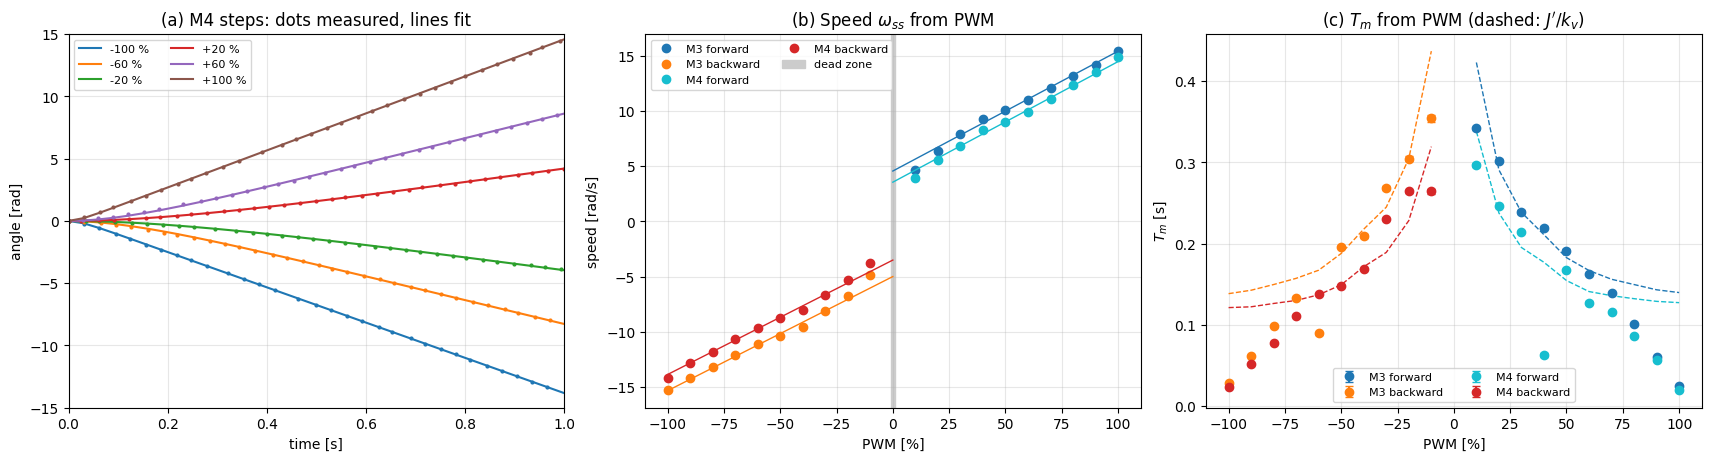

In [4]:
COLORS = {('M3', 1): 'tab:blue', ('M3', -1): 'tab:orange', ('M4', 1): 'tab:cyan', ('M4', -1): 'tab:red'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
theta, t, pwm = load('steps_M4.txt')                                      # (a) step fits of M4
for a, b in blocks(pwm):
    if pwm[a] in (-100, -60, -20, 20, 60, 100):
        ts = t[a:b] - t[a]
        dots, = ax[0].plot(ts, theta[a:b] - theta[a], '.', ms=4)
        ax[0].plot(ts, model(ts, *steps['M4'].loc[pwm[a], ['w_ss', 'T_m']]), color=dots.get_color(), label=f'{pwm[a]:+.0f} %')
for (m, s), c in COLORS.items():                                          # (b) speed and (c) time constant vs PWM
    x, pp = steps[m][np.sign(steps[m].index) == s], np.linspace(0, 100 * s, 50)
    ax[1].plot(x.index, x.w_ss, 'o', color=c, label=f'{m} {NAME[s]}')
    ax[1].plot(pp, line(m, s, pp), color=c, lw=1)
    ax[2].errorbar(x.index, x.T_m, x.T_err, fmt='o', color=c, capsize=3, label=f'{m} {NAME[s]}')
    ax[2].plot(x.index, J[m] / k_v[m][x.index], '--', color=c, lw=1)     # T_m = J' / k_v (section 5)
ax[1].axvspan(-1, 1, color='0.8', label='dead zone')
ax[0].set(title='(a) M4 steps: dots measured, lines fit', xlim=(0, 1), ylim=(-15, 15), xlabel='time [s]', ylabel='angle [rad]')
ax[1].set(title=r'(b) Speed $\omega_{ss}$ from PWM', xlabel='PWM [%]', ylabel='speed [rad/s]')
ax[2].set(title=r"(c) $T_m$ from PWM (dashed: $J'/k_v$)", xlabel='PWM [%]', ylabel=r'$T_m$ [s]')
for a_ in ax:
    a_.legend(ncol=2)
plt.show()

**Figure 1.** (a) M4 steps with the fitted model. (b) $\omega_{ss}$ against PWM with the line of each direction; grey: dead zone. (c) $T_m$ with error bars; dashed: $J'/k_v$ (section 5).

- The model follows each step from the first sample, so there is no inductance delay (a).
- $T_m$ is **not constant**: 0.342 s at 10 % but 0.025 s at 100 % (M3 forward), with the same load (c). The low points at −60 % (M3) and +40 % (M4) are bad fits.
- The lines reach zero speed 32.5 to 48.3 % PWM on the other side (b), so $\omega_{ss}$ is not proportional to $U$.

## 4. Three outcomes
### 4.1 Dead zone
On the slow triangle the wheel stood still only at 0 and ±1 % (Table 2): the dead zone is **at most 1 % PWM (0.12 V)** on both motors, both ways. Near zero the speed jumps up and then follows the line (Figure 2a). This S-shape is why the lines miss zero.



### 4.2 Coulomb + viscous friction
**Idea.** After every step the PWM is 0 for 1 s. With no voltage, no current flows, so the motor gives no torque and no back-EMF braking. The wheel keeps turning on its own momentum (coasting), and only friction slows it down. So coasting measures friction alone.

**Two kinds of friction** (both written as deceleration, in rad/s²)
- **Coulomb friction** $a$: a constant slowing, the same at any speed, always against the motion, like dry rubbing in the gears and brushes. Its direction follows the motion: $-a\,\mathrm{sign}(\omega)$.
- **Viscous friction** $\beta\omega$: grows in proportion to the speed, like the drag of grease in the gearbox and bearings. $\beta$ is in 1/s.

**Coasting equation.** Forward ($\omega>0$, so $\mathrm{sign}(\omega)=1$):

$$\dot\omega=-a-\beta\omega=-\beta\left(\omega+\frac{a}{\beta}\right)$$

**Solving it,** starting from speed $\omega_0$ and angle 0:
1. The bracket $\omega+a/\beta$ shrinks exponentially with rate $\beta$, so the speed is

$$\omega(t)=\left(\omega_0+\frac{a}{\beta}\right)e^{-\beta t}-\frac{a}{\beta}$$

2. Integrating once more gives the angle, which the encoder measures:

$$\theta(t)=\frac{1}{\beta}\left(\omega_0+\frac{a}{\beta}\right)\left(1-e^{-\beta t}\right)-\frac{a}{\beta}\,t$$

3. The wheel stops when $\omega(t_s)=0$:

$$t_s=\frac{1}{\beta}\ln\left(1+\frac{\beta\omega_0}{a}\right)$$

After $t_s$ Coulomb friction holds the wheel still, so the angle stays at $\theta(t_s)$.

**What each part does**
- **Viscous only** ($a=0$): $\omega=\omega_0e^{-\beta t}$. The speed gets ever closer to 0 but never reaches it.
- **Coulomb only** ($\beta=0$): $\omega=\omega_0-at$. The speed falls in a straight line and stops at $t=\omega_0/a$.
- **Both:** viscous friction slows the wheel strongly at high speed, and Coulomb friction brings it to a full stop.

**The course model** at $U=0$ gives $\dot\omega=-\omega/T_m$: viscous-like braking with rate $1/T_m$ (about 6 to 7 1/s), so the wheel turns only $\omega_0T_m$ after power-off. It assumes back-EMF still brakes the wheel, but at PWM 0 no current flows.

**How the fit works**
- $\omega_0$ is $\omega_{ss}$ of the step just before, from Table 1: the wheel was at that steady speed when the PWM went to 0.
- For backward, the angle's sign is flipped, so the same formula works.
- All 10 coasting blocks of one motor and direction are fitted together, so one pair $a$, $\beta$ must match every starting speed at once. That is what separates the two frictions: they change the coasting distance differently as $\omega_0$ grows.
- Three versions are fitted: both, Coulomb only and viscous only (the missing part is set to a tiny 0.001, because the formula divides by $\beta$ and $a$). The angle RMSE of each (Table 3) shows which friction is really there.

In [5]:
def coast(X, a, beta):                                                    # angle after power-off from speed w0 (formula above)
    t, w0 = X
    t = np.minimum(t, np.log(1 + beta * w0 / a) / beta)                   # after t_s the wheel stays still
    return (w0 + a / beta) * (1 - np.exp(-beta * t)) / beta - a / beta * t

rows = []                                                                 # every coasting sample
for m in MOTORS:
    theta, t, pwm = load(f'steps_{m}.txt')
    bl = blocks(pwm)
    for (i, j), (c, d) in zip(bl, bl[1:]):
        if pwm[i] != 0 and pwm[c] == 0:                                   # a step, then its coasting block
            s = np.sign(pwm[i])
            for k in range(c, d):
                rows.append([m, s, c, t[k] - t[c], abs(steps[m].w_ss[pwm[i]]), s * (theta[k] - theta[c])])
coasting = pd.DataFrame(rows, columns=['motor', 's', 'block', 't', 'w0', 'angle'])

fric, rows = {}, []
for (m, s), x in coasting.groupby(['motor', 's']):
    X, y, err = (x.t.values, x.w0.values), x.angle.values, []
    for f, p0 in [(coast, [10, 1]), (lambda X, a: coast(X, a, 1e-3), [10]), (lambda X, beta: coast(X, 1e-3, beta), [1])]:
        p = optimize.curve_fit(f, X, y, p0=p0, bounds=(1e-3, 100))[0]
        err.append(np.degrees(np.sqrt(np.mean((y - f(X, *p)) ** 2))))     # RMSE of the angle [deg]
        fric.setdefault((m, s), p)                                        # keep the first fit: Coulomb + viscous
    rows.append([m, NAME[s], *fric[m, s], *err])
pd.DataFrame(rows, columns=['motor', 'direction', 'a [rad/s²]', 'beta [1/s]', 'RMSE both [deg]',
                            'RMSE Coulomb only [deg]', 'RMSE viscous only [deg]']).set_index(['motor', 'direction']).round(2)

a [rad/s²]  beta [1/s]  RMSE both [deg]  \
motor direction                                            
M3    backward        10.29        0.97             4.64   
      forward         11.08        1.23            25.81   
M4    backward         6.03        2.84            14.98   
      forward          2.00        4.10            22.87   

                 RMSE Coulomb only [deg]  RMSE viscous only [deg]  
motor direction                                                    
M3    backward                     13.22                    21.26  
      forward                      28.36                    31.62  
M4    backward                     23.43                    17.74  
      forward                      33.17                    23.17

**Table 3.** Friction from coasting, and the angle RMSE of the three friction models.

M3: wheel turns 0.8 to 5.9 rad after power-off; distance RMSE course model 1.73 rad, friction model 0.44 rad
M4: wheel turns 0.4 to 3.8 rad after power-off; distance RMSE course model 0.85 rad, friction model 0.42 rad


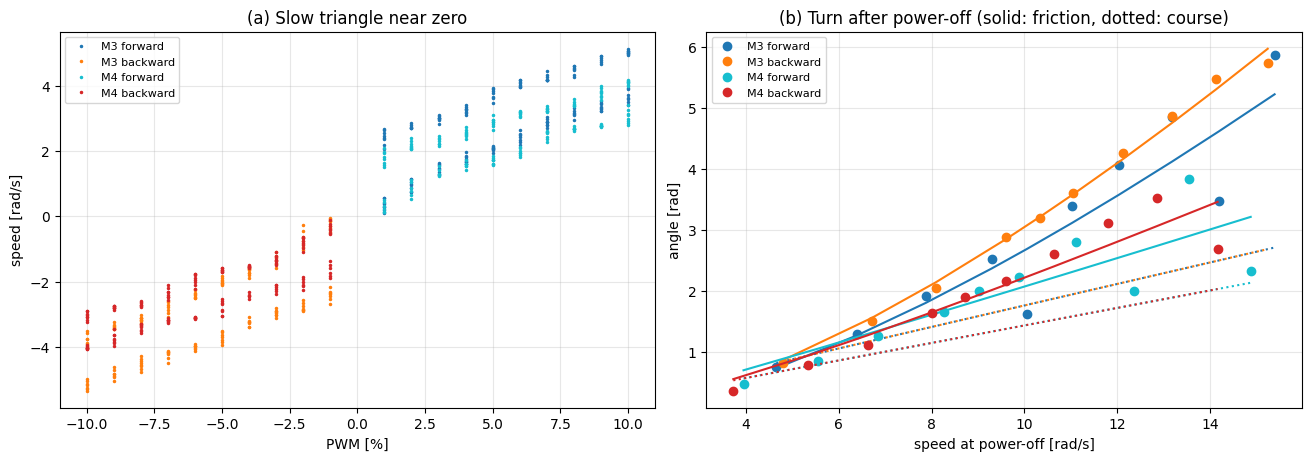

In [6]:
dist = coasting.groupby(['motor', 's', 'block']).agg(w0=('w0', 'first'), measured=('angle', 'last')).reset_index()
dist['course'] = [w0 * par.loc[m, 'mean T_m [s]'].mean() for m, w0 in zip(dist.motor, dist.w0)]          # course model: w0 T_m
dist['friction'] = [coast((1.0, w0), *fric[m, s]) for m, s, w0 in zip(dist.motor, dist.s, dist.w0)]    # friction model
for m, x in dist.groupby('motor'):
    e = lambda col: np.sqrt(np.mean((x[col] - x.measured) ** 2))
    print(f'{m}: wheel turns {x.measured.min():.1f} to {x.measured.max():.1f} rad after power-off; '
          f'distance RMSE course model {e("course"):.2f} rad, friction model {e("friction"):.2f} rad')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for (m, s), c in COLORS.items():
    theta, t, pwm = load(f'triangle_{m}.txt')                             # (a) triangle near zero
    z = (abs(pwm) <= 10) & (np.sign(pwm) == s)
    ax[0].plot(pwm[z], speed(theta, t)[z], '.', color=c, ms=3, label=f'{m} {NAME[s]}')
    x = dist[(dist.motor == m) & (dist.s == s)].sort_values('w0')         # (b) coasting distance
    ax[1].plot(x.w0, x.measured, 'o', color=c, label=f'{m} {NAME[s]}')
    ax[1].plot(x.w0, x.friction, '-', color=c)
    ax[1].plot(x.w0, x.course, ':', color=c)
ax[0].set(title='(a) Slow triangle near zero', xlabel='PWM [%]', ylabel='speed [rad/s]')
ax[1].set(title='(b) Turn after power-off (solid: friction, dotted: course)',
          xlabel='speed at power-off [rad/s]', ylabel='angle [rad]')
for a_ in ax:
    a_.legend()
plt.show()

**Figure 2.** (a) Slow triangle near zero PWM. (b) Wheel turn after power-off. Dots: measured; solid: friction model; dotted: course model ($\omega_0 T_m$).

- **Both parts are needed:** together they give the lowest RMSE in all four cases. M3 is mostly Coulomb friction, M4 mostly viscous.
- Friction cuts the coasting error from 1.73 to 0.44 rad (M3) and from 0.85 to 0.42 rad (M4). At ±100 % M4 stops sooner, so its friction grows faster than linear.

### 4.3 Backward ≥ forward
I compare each backward value with the forward value of the same motor: $100\,(\text{backward}/\text{forward}-1)$, in %. A positive number means backward is larger, a negative number means it is smaller. Speeds are compared at the same |PWM|, and coasting friction at the same speed, 10 rad/s, so the comparison is fair.

**Table 4.** Backward against forward [%].

In [7]:
rows = {}
for m in MOTORS:                                                          # backward / forward - 1, in %
    F, B, w = par.loc[(m, 'forward')], par.loc[(m, 'backward')], steps[m].w_ss
    friction = {s: fric[m, s][0] + fric[m, s][1] * 10 for s in (1, -1)}  # coasting friction at 10 rad/s
    rows[m] = {**{c: B[c] / F[c] for c in ['slope [rad/s per %]', 'k_e [V s/rad]', 'mean T_m [s]']},
               **{f'speed at {p} %': -w[-p] / w[p] for p in (10, 50, 100)}, 'coasting friction': friction[-1] / friction[1]}
(100 * (pd.DataFrame(rows).T - 1)).round(1)

,slope [rad/s per %],k_e [V s/rad],mean T_m [s],speed at 10 %,speed at 50 %,speed at 100 %,coasting friction
M3,-4.7,5.0,-2.0,3.3,2.8,-1.0,-14.3
M4,-5.1,5.4,6.1,-5.6,-3.4,-4.8,-19.9


- **$k_e$ is about 5 % larger backward on both motors** (slope 4.7 and 5.1 % smaller): backward needs more volts for every extra rad/s.
- **Speed depends on the motor.** On M4 backward is slower at every PWM (−5.6, −3.4 and −4.8 %). On M3 backward has a bigger jump near zero (its line misses zero by 48.3 % instead of 42.0 %, Table 2), so it is faster at 10 and 50 % and slower only at 100 %.
- **$T_m$ shows no clear direction effect:** −2.0 % on M3 but +6.1 % on M4.
- **Not friction:** backward has 14 to 20 % *less* coasting friction, which would make it faster, not slower. So the cause is in the motor itself. A common cause in brushed motors is the brush position, which favours one direction; my data cannot check this.
- **Effect:** on the symmetric slow chirp the wheel drifts forward, 13.1 rad (M3) and 17.2 rad (M4). The improved model, with separate constants for each direction, reproduces this (5.1).



## 5. Improved formula
**Step 1: add friction to the course model** ($L\approx 0$):

$$J\dot\omega=k_m i-b\,\omega-M_c\,\mathrm{sign}(\omega),\quad i=\frac{U-k_e\omega}{R}\quad\Rightarrow\quad J'\dot\omega=U-k_v\,\omega-U_c\,\mathrm{sign}(\omega)$$

with $J'=JR/k_m$ (inertia), $k_v=k_e+Rb/k_m$ (back-EMF and viscous friction together) and $U_c=RM_c/k_m$ (Coulomb friction in volts). Without friction this is the course model, with $T_m=J'/k_v$.

**Step 2: compare with my data**
- A dead zone $U_c$ would shift the speed line to the right. My lines are shifted the other way: they reach zero at −33 to −48 % (Figure 1b), because near zero the speed jumps up within a few percent.
- $T_m$ should be constant. Mine falls, because the measured braking $k_v=U/\omega_{ss}$ grows with PWM while $J'$ stays constant (Figure 1c, dashed).
- The coasting friction in volts, $J'a$ = 0.2 to 1.2 V (Table 5), is larger than the 0.12 V that already turns the wheel. Either friction is smaller while driven, or the driver gives extra voltage at low PWM; my data cannot tell which.

**Step 3: improved model**, for each motor and direction:

$$\omega_{ss}(U)=\mathrm{sign}(U)\left[\omega_0\left(1-e^{-|U|/U_1}\right)+\frac{|U|}{k}\right]$$

$$\mathrm{PWM}\ne 0:\quad J'\dot\omega=U-\frac{U}{\omega_{ss}(U)}\,\omega\qquad\qquad \mathrm{PWM}=0:\quad \dot\omega=-a\,\mathrm{sign}(\omega)-\beta\omega$$

- $\omega_{ss}(U)$ is the measured S-shape: a quick rise of $\omega_0$ within about $U_1$, then a line with slope $1/k$ (fixes Figure 1b).
- The driven equation is Step 1 with $k_v$ replaced by the measured $U/\omega_{ss}(U)$. It settles at $\omega_{ss}(U)$, and its time constant $T_m(U)=J'\omega_{ss}(U)/U$ falls with PWM (fixes Figure 1c).
- At PWM 0 only friction acts (fixes coasting, Figure 2b), and each direction has its own constants (fixes the drift, 4.3).
- $\omega_0$, $U_1$, $k$ are fitted to Table 1, $J'$ is the median of $T_mU/\omega_{ss}$ for $|\mathrm{PWM}|\le 60\,\%$, and $a$, $\beta$ come from Table 3. The complex signals are not used, so they are a fair test (5.1).

In [8]:
def w_static(U, w0, U1, k):                                               # improved static curve: |U| -> |w_ss|
    return w0 * (1 - np.exp(-abs(U) / U1)) + abs(U) / k

static, rows = {}, []
for m in MOTORS:
    for s in (1, -1):
        x = steps[m][np.sign(steps[m].index) == s]
        U = abs(x.index.values) / 100 * bat.U[f'steps_{m}.txt']
        static[m, s] = optimize.curve_fit(w_static, U, abs(x.w_ss.values), p0=[4, 0.5, 1])[0]
        err = np.sqrt(np.mean((abs(x.w_ss.values) - w_static(U, *static[m, s])) ** 2))
        rows.append([m, NAME[s], *static[m, s], J[m], *fric[m, s], J[m] * fric[m, s][0], err])
pd.DataFrame(rows, columns=['motor', 'direction', 'w0 [rad/s]', 'U1 [V]', 'k [V s/rad]', "J' [V s²/rad]", 'a [rad/s²]',
                            'beta [1/s]', "J'a [V]", 'w_ss RMSE [rad/s]']).set_index(['motor', 'direction']).round(3)

w0 [rad/s]  U1 [V]  k [V s/rad]  J' [V s²/rad]  a [rad/s²]  \
motor direction                                                               
M3    forward         4.867   0.888        1.107          0.105      11.077   
      backward        5.430   0.977        1.188          0.105      10.294   
M4    forward         3.466   0.680        1.032          0.099       1.998   
      backward        3.554   0.827        1.112          0.099       6.026   

                 beta [1/s]  J'a [V]  w_ss RMSE [rad/s]  
motor direction                                          
M3    forward         1.226    1.160              0.126  
      backward        0.970    1.078              0.146  
M4    forward         4.104    0.198              0.170  
      backward        2.844    0.596              0.153

**Table 5.** Constants of the improved model, Coulomb friction in volts ($J'a$), and the RMSE of $\omega_{ss}(U)$.

### 5.1 Test on the complex signals
`odeint` with the recorded input (`np.interp`). The course model uses the mean $k_e$ and $T_m$ of each motor, without a dead zone (mine is at most 1 %). Measured speed: `np.gradient`, then a moving average of 3 samples (about 0.15 s).

In [9]:
def simulate(name, accel):                                                # odeint with the recorded input
    theta, t, pwm = load(name)
    t_log, U_log = t - t[0], pwm / 100 * bat.U[name]
    def motor(state, t):
        speed, angle = state
        p, u = np.interp(t, t_log, pwm), np.interp(t, t_log, U_log)      # recorded input [% PWM] and [V]
        return np.array([accel(p, u, speed), speed])                     # differential equation for the motor state
    return odeint(motor, [0, 0], t_log, hmax=0.005)                       # y[:,0] speed, y[:,1] angle

def course(m):                                                            # course model, mean k_e and T_m of the motor
    k_e, T_m = par.loc[m, 'k_e [V s/rad]'].mean(), par.loc[m, 'mean T_m [s]'].mean()
    return lambda p, u, w: u / (T_m * k_e) - w / T_m

def improved(m):                                                          # improved model (formula above)
    def accel(p, u, w):
        if abs(p) >= 0.5:                                                 # driven: J' dw/dt = U - (U / w_ss(U)) w
            w_ss = np.sign(u) * w_static(u, *static[m, np.sign(u)])
            return (u - u / w_ss * w) / J[m]
        if abs(w) < 0.05:                                                 # stopped: friction holds the wheel
            return -w / 0.01
        a, beta = fric[m, np.sign(w)]                                     # power off: friction only
        return -np.sign(w) * a - beta * w
    return accel

fit = lambda y, yh: 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - np.mean(y)))
rmse = lambda y, yh: np.sqrt(np.mean((y - yh) ** 2))
meas, sims, rows = {}, {}, []
for signal in ['signal', 'chirp', 'triangle']:
    for m in MOTORS:
        name = f'{signal}_{m}.txt'
        theta, t, pwm = load(name)
        meas[name] = (t - t[0], theta - theta[0], speed(theta, t), pwm)  # time, angle, measured speed, PWM
        for model_name, accel in [('course', course(m)), ('improved', improved(m))]:
            y = sims[name, model_name] = simulate(name, accel)
            rows.append([signal, m, model_name, fit(meas[name][1], y[:, 1]), fit(meas[name][2], y[:, 0]),
                         rmse(meas[name][1], y[:, 1]), rmse(meas[name][2], y[:, 0])])
for m in MOTORS:                                                          # where is the error largest? square wave vs chirp
    tt, th, w, pwm = meas[f'signal_{m}.txt']
    for part, z in [('square wave', tt < 4), ('chirp', tt >= 4)]:
        f_course, f_improved = (fit(w[z], sims[f'signal_{m}.txt', k][z, 0]) for k in ('course', 'improved'))
        print(f'{m} {part}: speed fit {f_course:.1f} % (course) -> {f_improved:.1f} % (improved)')
pd.DataFrame(rows, columns=['signal', 'motor', 'model', 'fit angle %', 'fit speed %', 'RMSE angle [rad]',
                            'RMSE speed [rad/s]']).set_index(['signal', 'motor', 'model']).round(2)

M3 square wave: speed fit 59.4 % (course) -> 85.2 % (improved)
M3 chirp: speed fit 53.9 % (course) -> 76.0 % (improved)
M4 square wave: speed fit 67.8 % (course) -> 83.4 % (improved)
M4 chirp: speed fit 56.9 % (course) -> 65.9 % (improved)


fit angle %  fit speed %  RMSE angle [rad]  \
signal   motor model                                                  
signal   M3    course         -52.83        56.35              3.30   
               improved        35.55        79.72              1.39   
         M4    course         -37.64        61.69              5.25   
               improved        39.69        72.75              2.30   
chirp    M3    course         -86.19        50.66              4.85   
               improved         2.32        78.86              2.54   
         M4    course        -166.82        58.40              8.12   
               improved        64.42        83.96              1.08   
triangle M3    course          -3.21        39.81             49.16   
               improved        90.69        96.13              4.44   
         M4    course          -0.13        47.09             40.35   
               improved        96.40        95.23              1.45   

                         RMSE speed [rad/s]  
signal   motor model                         
signal   M3    course                  2.15  
               improved                1.00  
         M4    course                  1.80  
               improved                1.28  
chirp    M3    course                  2.77  
               improved                1.18  
         M4    course                  2.19  
               improved                0.85  
triangle M3    course                  4.42  
               improved                0.28  
         M4    course                  3.32  
               improved                0.30

**Table 6.** Fit $=100\,(1-\|y-\hat y\|/\|y-\bar y\|)$ and RMSE on the three complex signals.

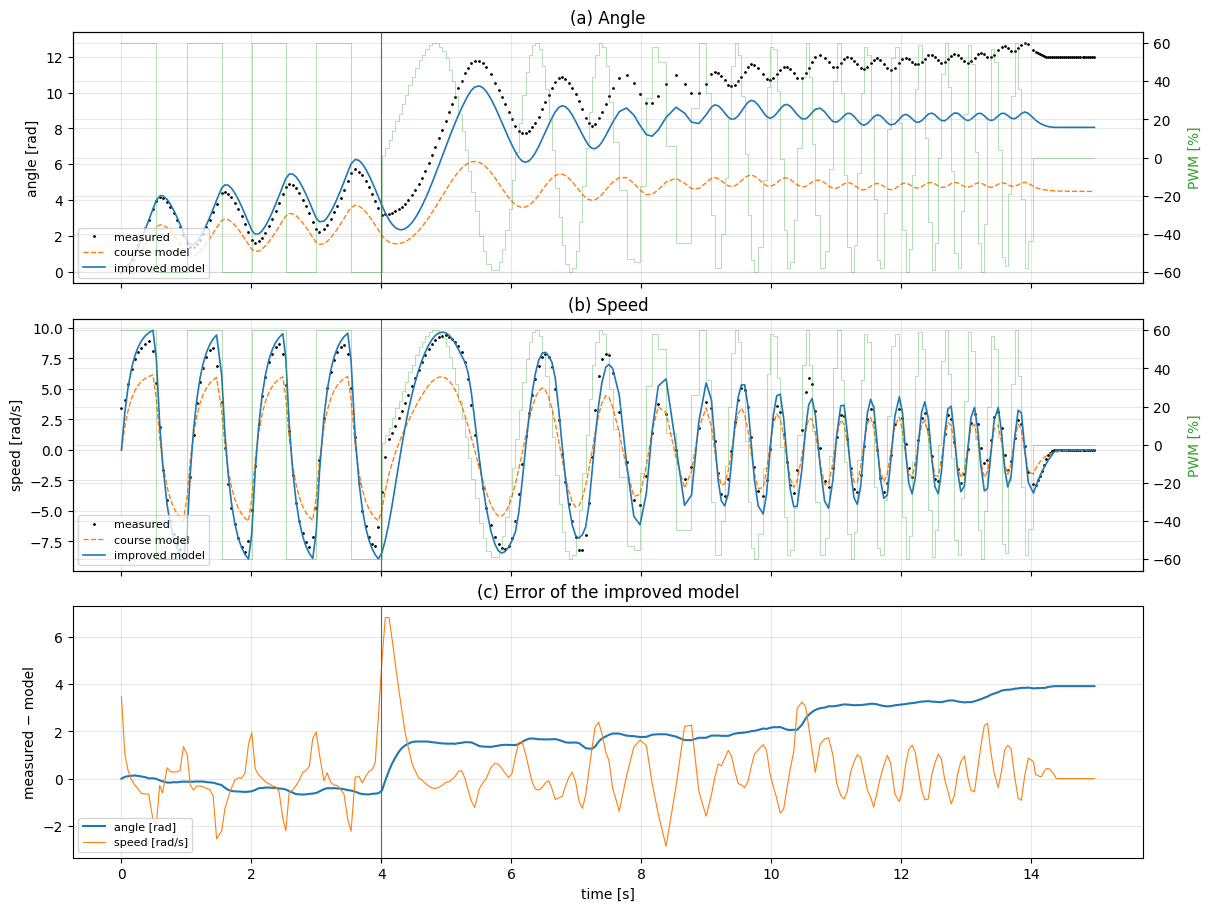

In [10]:
name = 'signal_M4.txt'                                                    # the complex signal: square wave + chirp, M4
tt, th, w, pwm = meas[name]
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (y, k, label) in zip(axs, [(th, 1, 'angle [rad]'), (w, 0, 'speed [rad/s]')]):   # (a) angle, (b) speed
    ax.plot(tt, y, 'k.', ms=2, label='measured')
    ax.plot(tt, sims[name, 'course'][:, k], '--', color='tab:orange', lw=1, label='course model')
    ax.plot(tt, sims[name, 'improved'][:, k], color='tab:blue', lw=1.2, label='improved model')
    pa = ax.twinx()                                                       # input PWM on the right axis
    pa.step(tt, pwm, where='post', color='tab:green', lw=.6, alpha=.4)
    pa.set_ylabel('PWM [%]', color='tab:green')
    ax.set(ylabel=label)
axs[2].plot(tt, th - sims[name, 'improved'][:, 1], label='angle [rad]')   # (c) measured - improved model
axs[2].plot(tt, w - sims[name, 'improved'][:, 0], lw=.8, label='speed [rad/s]')
axs[0].set_title('(a) Angle')
axs[1].set_title('(b) Speed')
axs[2].set(title='(c) Error of the improved model', xlabel='time [s]', ylabel='measured − model')
for ax in axs:
    ax.axvline(4, color='0.4', lw=.8)                                     # square wave ends, chirp starts
    ax.legend(loc='lower left')
plt.show()

**Figure 3.** The complex signal (square wave + chirp) on M4: (a) angle and (b) speed, measured and simulated, with the input PWM in green (right axis); (c) error of the improved model over time. Grey line: the square wave ends and the chirp starts. The slow triangle and slow chirp results are in Table 6 and Figure 4.

M3: measured ratio 1.55 at 0.36 Hz, 0.63 at 2.01 Hz; corner 1/(2 pi T_m) = 0.90 Hz
M3: slow chirp end angle (drift) measured +13.1 rad, course model +7.0, improved model +13.6
M4: measured ratio 1.36 at 0.36 Hz, 0.69 at 2.00 Hz; corner 1/(2 pi T_m) = 1.11 Hz
M4: slow chirp end angle (drift) measured +17.2 rad, course model +7.7, improved model +16.4


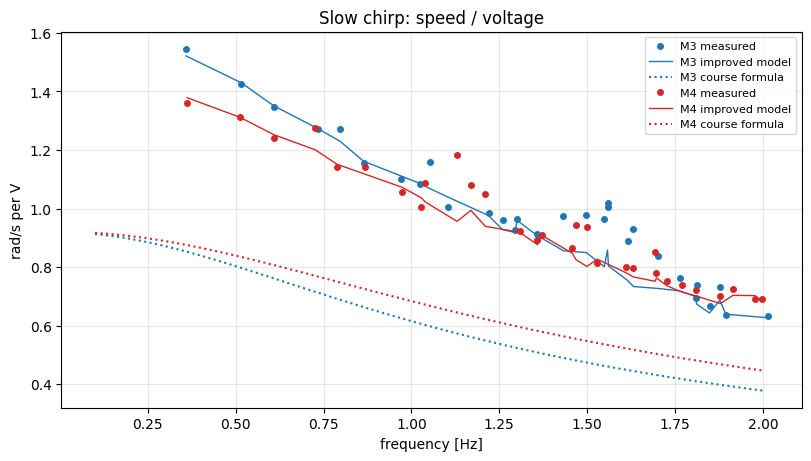

In [11]:
def ratio(name, angle):                                                   # speed swing / voltage swing in every input period
    tt, th, w, pwm = meas[name]
    U, w = pwm / 100 * bat.U[name], np.gradient(angle, tt)
    z = np.flatnonzero(np.diff(U >= 0) != 0)                              # zero crossings of the input
    r = np.array([[1 / (tt[j] - tt[i]), np.ptp(w[i:j]) / np.ptp(U[i:j])] for i, j in zip(z[:-2:2], z[2::2])])
    return r[np.argsort(r[:, 0])].T                                       # frequency [Hz], ratio [rad/s per V]

f = np.linspace(0.1, 2, 100)
plt.figure(figsize=(8, 4.5))
for m, c in [('M3', 'tab:blue'), ('M4', 'tab:red')]:
    name = f'chirp_{m}.txt'
    k_e, T_m = par.loc[m, 'k_e [V s/rad]'].mean(), par.loc[m, 'mean T_m [s]'].mean()
    r = ratio(name, meas[name][1])
    plt.plot(*r, 'o', color=c, ms=4, label=f'{m} measured')
    plt.plot(*ratio(name, sims[name, 'improved'][:, 1]), color=c, lw=1, label=f'{m} improved model')
    plt.plot(f, 1 / (k_e * np.sqrt(1 + (2 * np.pi * f * T_m) ** 2)), ':', color=c, label=f'{m} course formula')
    print(f'{m}: measured ratio {r[1][0]:.2f} at {r[0][0]:.2f} Hz, {r[1][-1]:.2f} at {r[0][-1]:.2f} Hz; '
          f'corner 1/(2 pi T_m) = {1 / (2 * np.pi * T_m):.2f} Hz')
    print(f'{m}: slow chirp end angle (drift) measured {meas[name][1][-1]:+.1f} rad, '
          f'course model {sims[name, "course"][-1, 1]:+.1f}, improved model {sims[name, "improved"][-1, 1]:+.1f}')
plt.title('Slow chirp: speed / voltage')
plt.xlabel('frequency [Hz]')
plt.ylabel('rad/s per V')
plt.legend()
plt.show()

**Figure 4.** Slow chirp: speed swing / voltage swing in every period. Dots: measured; solid: improved model; dotted: course formula $1/(k_e\sqrt{1+(2\pi fT_m)^2})$.

- **Speed fit, course → improved:** triangle 39.8 → 96.1 % (M3) and 47.1 → 95.2 % (M4); slow chirp 50.7 → 78.9 % and 58.4 → 84.0 %; square wave + chirp 56.4 → 79.7 % and 61.7 → 72.8 %. The angle fit is lower on the chirps, because the angle adds up every speed error.
- **Chirp:** the ratio falls from 1.55 (M3) and 1.36 (M4) at 0.36 Hz to 0.63 and 0.69 at 2 Hz, far above the course formula; the improved model follows it.
- **Drift:** the wheel ends 13.1 and 17.2 rad forward (backward ≥ forward). The improved model gives 13.6 and 16.4 rad, the course model 7.0 and 7.7 rad.

## 6. Artifact analysis

M3: speed at +100 / -100 % is -0.1 / -0.5 % off the line
M4: speed at +100 / -100 % is +2.8 / +2.2 % off the line
M3 vs M4: slope -0.6 %, k_e +0.5 %, mean T_m +27.9 %
mean sampling interval [ms]: steps_M4 32.5, steps_M4_run2 32.5, steps_M3 32.5, signal_M4 53.3, signal_M3 51.6, triangle_M4 53.4, triangle_M3 52.9, chirp_M4 50.6, chirp_M3 54.9
sampling interval: min 23 ms, max 152 ms
battery: 11.545 V at the start, 11.493 V at the end, largest drop in one run 0.013 V
repeat run: w_ss of run 2 / run 1 = 1.007
speed noise at +60 %: raw 0.39 rad/s, moving average 0.17 rad/s
steps_M3.txt: change with motor off 0 deg | first angle 56 deg, net turn of the series -425 deg | first time() 69 ms
steps_M4.txt: change with motor off 0 deg | first angle 15104 deg, net turn of the series +429 deg | first time() 101 ms
steps_M4_run2.txt: change with motor off 0 deg | first angle 15533 deg, net turn of the series +430 deg | first time() 56 ms


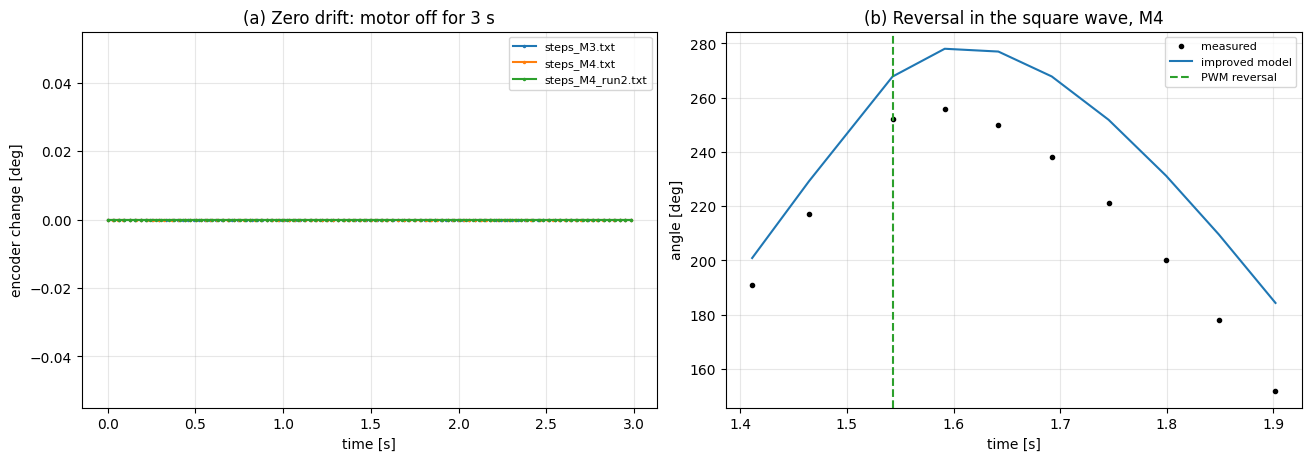

In [12]:
for m in MOTORS:                                                          # saturation: speed at +-100 % against the line
    off = [100 * (steps[m].w_ss[s * 100] / line(m, s, s * 100) - 1) for s in (1, -1)]
    print(f'{m}: speed at +100 / -100 % is {off[0]:+.1f} / {off[1]:+.1f} % off the line')
F3, F4 = par.loc[('M3', 'forward')], par.loc[('M4', 'forward')]           # motor-to-motor spread
spread = [f'{c.split(" [")[0]} {100 * (F3[c] / F4[c] - 1):+.1f} %' for c in ['slope [rad/s per %]', 'k_e [V s/rad]', 'mean T_m [s]']]
print('M3 vs M4:', ', '.join(spread))
dt = pd.Series({name: np.diff(load(name)[1]) * 1000 for name in bat.index})   # sampling interval of every run [ms]
print('mean sampling interval [ms]:', ', '.join(f'{n[:-4]} {d.mean():.1f}' for n, d in dt.items()))
print(f'sampling interval: min {min(map(min, dt)):.0f} ms, max {max(map(max, dt)):.0f} ms')
print(f'battery: {bat.U_before.max():.3f} V at the start, {bat.U_after.min():.3f} V at the end, '
      f'largest drop in one run {(bat.U_before - bat.U_after).max():.3f} V')
print(f'repeat run: w_ss of run 2 / run 1 = {(steps["M4 run 2"].w_ss / steps["M4"].w_ss).mean():.3f}')
theta, t, pwm = load('steps_M4.txt')                                      # encoder noise at +60 %, steady part
z = (pwm == 60) & (t > t[pwm == 60][0] + 1)
print(f'speed noise at +60 %: raw {np.gradient(theta, t)[z].std():.2f} rad/s, moving average {speed(theta, t)[z].std():.2f} rad/s')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name in ['steps_M3.txt', 'steps_M4.txt', 'steps_M4_run2.txt']:        # (a) zero drift: the first 3 s, motor off
    theta, t, pwm = load(name)
    off = t - t[0] < 3
    ax[0].plot(t[off] - t[0], np.degrees(theta[off] - theta[0]), '.-', ms=3, label=name)
    print(f'{name}: change with motor off {np.degrees(np.ptp(theta[off])):.0f} deg | first angle {np.degrees(theta[0]):.0f} deg, '
          f'net turn of the series {np.degrees(theta[-1] - theta[0]):+.0f} deg | first time() {1000 * t[0]:.0f} ms')
tt, th, w, pwm = meas['signal_M4.txt']                                    # (b) third reversal of the square wave
i = np.flatnonzero((np.diff(np.sign(pwm)) != 0) & (tt[1:] < 4))[2] + 1
z = (tt > tt[i] - .15) & (tt < tt[i] + .4)
ax[1].plot(tt[z], np.degrees(th[z]), 'k.', label='measured')
ax[1].plot(tt[z], np.degrees(sims['signal_M4.txt', 'improved'][z, 1]), label='improved model')
ax[1].axvline(tt[i], color='tab:green', ls='--', label='PWM reversal')
ax[0].set(title='(a) Zero drift: motor off for 3 s', xlabel='time [s]', ylabel='encoder change [deg]')
ax[1].set(title='(b) Reversal in the square wave, M4', xlabel='time [s]', ylabel='angle [deg]')
for a_ in ax:
    a_.legend()
plt.show()

**Figure 5.** (a) Encoder with the motor off. (b) One square-wave reversal of M4.

- **Forward vs backward:** slope −4.7 and −5.1 %, $T_m$ −2.0 and +6.1 % (M3, M4; Table 4). *Cause:* the motor itself (4.3).
- **Zero drift:** 0° with the motor off (a). The count is not reset between programs and `time()` starts at 56 to 101 ms, so every step is measured from its own first sample; both M4 series end +429° and +430° from their start. *Cause:* the encoder counts only real rotation.
- **Dead zone:** at most 1 % PWM (4.1). *Cause:* little Coulomb friction with free wheels.
- **Saturation:** none; within 3 % of the line at ±100 %. *Cause:* free wheels need little current.
- **Coasting:** 0.4 to 5.9 rad, far more than $\omega_0T_m$ (4.2, Figure 2b). *Cause:* only friction stops the wheel.
- **Gear backlash:** no flat part at the reversal (b). *Cause:* the play is below one encoder degree.
- **Sampling jitter:** 5 ms Timer, but on average 32.5 ms (steps) and 51 to 55 ms (other runs), from 23 to 152 ms; long intervals cause single speed spikes (Figure 3b). *Cause:* Write To File and the scheduler.
- **Battery sag:** 11.545 V at the start, 11.493 V at the end, at most 0.013 V in one run; run 2 matches run 1 within 0.7 %. *Cause:* low current and short runs.
- **Encoder noise:** 0.39 rad/s raw, 0.17 rad/s with the moving average. *Cause:* whole degrees over a short $\Delta t$.
- **Motor-to-motor spread:** slope −0.6 %, $k_e$ +0.5 %, $T_m$ +27.9 % (M3 vs M4). *Cause:* M3 has a 6 % larger $J'$ (Table 5).
- **Other, drift:** 13.1 and 17.2 rad forward on the slow chirp (5.1). *Cause:* backward ≥ forward.